28242 -> 13130 lignes (attendu : 13130)
NaN: 0
outliers flaggés (3xIQR): 0
rendements < 0.1 t/ha: 25


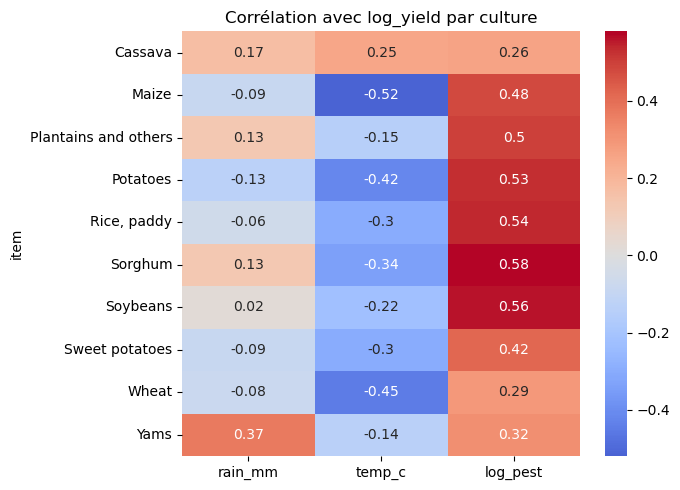

R² test (optimiste, split aléatoire): 0.973
item        1.767773
log_pest    0.209123
temp_c      0.193770
rain_mm     0.150287
area        0.131281
year        0.038576
dtype: float64
CSV exporté: (13130, 9)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

SEED = 42

# ---------- 1. Chargement + dédoublonnage de la fusion ----------
raw = pd.read_csv("../data_source/yield_df.csv").drop(columns="Unnamed: 0")

# 1 ligne par (pays, culture, année) : moyenne des températures 
df = (raw.groupby(["Area", "Item", "Year"], as_index=False)
         .agg({"hg/ha_yield": "first",
               "average_rain_fall_mm_per_year": "first",
               "pesticides_tonnes": "first",
               "avg_temp": "mean"}))
df.columns = ["area", "item", "year", "yield_hg_ha", "rain_mm", "pesticides_t", "temp_c"]
print(f"{len(raw)} -> {len(df)} lignes (attendu : 13130)")
print("NaN:", df.isna().sum().sum())
df = df.dropna()

# ---------- 2. Unités et logs ----------
df["yield_t_ha"] = df["yield_hg_ha"] / 10_000
df["log_yield"] = np.log1p(df["yield_t_ha"])
df["log_pest"] = np.log1p(df["pesticides_t"])

# ---------- 3. Outliers : flag seulement (3xIQR par culture), on ne supprime pas ----------
q1 = df.groupby("item")["log_yield"].transform(lambda s: s.quantile(.25))
q3 = df.groupby("item")["log_yield"].transform(lambda s: s.quantile(.75))
iqr = q3 - q1
df["outlier"] = (df["log_yield"] < q1 - 3 * iqr) | (df["log_yield"] > q3 + 3 * iqr)
print("outliers flaggés (3xIQR):", df["outlier"].sum())
print("rendements < 0.1 t/ha:", (df["yield_t_ha"] < 0.1).sum())

# ---------- 4. Corrélations par culture ----------
num = ["log_yield", "rain_mm", "temp_c", "log_pest"]
corr_item = (df.groupby("item")[num].corr()["log_yield"]
               .unstack().drop(columns="log_yield").round(2))
plt.figure(figsize=(7, 5))
sns.heatmap(corr_item, annot=True, cmap="coolwarm", center=0)
plt.title("Corrélation avec log_yield par culture")
plt.tight_layout(); plt.show()

# ---------- 5. Importance des variables (RF) ----------
X = pd.get_dummies(df[["area", "item", "year", "rain_mm", "temp_c", "log_pest"]],
                   columns=["area", "item"])
y = df["log_yield"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=SEED)
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
print("R² test (optimiste, split aléatoire):", round(rf.score(Xte, yte), 3))

perm = permutation_importance(rf, Xte, yte, n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns)
grp = imp.groupby(lambda c: c.split("_")[0] if c.startswith(("area_", "item_")) else c).sum()
print(grp.sort_values(ascending=False))

# ---------- 6. Export du CSV consolidé ----------
out = df.drop(columns=["yield_hg_ha", "outlier"])
out.to_csv("../data/consolidated_yield.csv", index=False)
print("CSV exporté:", out.shape)

In [4]:
print(df[df["yield_t_ha"] < 0.1][["area", "item", "year", "yield_t_ha"]]
        .sort_values("yield_t_ha"))

             area      item  year  yield_t_ha
11826  Tajikistan  Soybeans  1992      0.0050
11827  Tajikistan  Soybeans  1993      0.0080
11837  Tajikistan  Soybeans  2004      0.0100
11828  Tajikistan  Soybeans  1994      0.0111
11840  Tajikistan  Soybeans  2008      0.0112
11829  Tajikistan  Soybeans  1995      0.0117
11831  Tajikistan  Soybeans  1997      0.0200
11830  Tajikistan  Soybeans  1996      0.0227
11836  Tajikistan  Soybeans  2002      0.0230
11833  Tajikistan  Soybeans  1999      0.0260
11832  Tajikistan  Soybeans  1998      0.0383
11838  Tajikistan  Soybeans  2006      0.0500
11834  Tajikistan  Soybeans  2000      0.0525
11835  Tajikistan  Soybeans  2001      0.0540
944    Azerbaijan   Sorghum  1992      0.0578
957    Azerbaijan  Soybeans  1993      0.0811
11839  Tajikistan  Soybeans  2007      0.0824
949    Azerbaijan   Sorghum  1997      0.0833
1364     Botswana     Maize  2013      0.0849
950    Azerbaijan   Sorghum  1998      0.0857
8477      Morocco   Sorghum  1995 

In [5]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score

groups = df["area"]
feat = ["area", "item", "year", "rain_mm", "temp_c", "log_pest"]
X = pd.get_dummies(df[feat], columns=["area", "item"])
y = df["log_yield"]

# R² honnête : pays de test jamais vus à l'entraînement
tr, te = next(GroupShuffleSplit(test_size=.2, random_state=SEED).split(X, y, groups))
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED).fit(X.iloc[tr], y.iloc[tr])
print("R² split par pays:", round(r2_score(y.iloc[te], rf.predict(X.iloc[te])), 3))

# Importance par groupe : on permute toutes les colonnes du groupe ensemble
rng = np.random.default_rng(SEED)
Xte, yte = X.iloc[te], y.iloc[te]
base = r2_score(yte, rf.predict(Xte))
blocks = {"item": [c for c in X if c.startswith("item_")],
          "area": [c for c in X if c.startswith("area_")],
          "year": ["year"], "rain_mm": ["rain_mm"],
          "temp_c": ["temp_c"], "log_pest": ["log_pest"]}
res = {}
for name, cols in blocks.items():
    drops = []
    for _ in range(5):
        Xp = Xte.copy()
        Xp[cols] = Xp[cols].iloc[rng.permutation(len(Xp))].values  # permute les lignes du bloc entier
        drops.append(base - r2_score(yte, rf.predict(Xp)))
    res[name] = np.mean(drops)
print(pd.Series(res).sort_values(ascending=False).round(3))

R² split par pays: 0.713
item        1.391
temp_c      0.121
log_pest    0.101
rain_mm     0.066
year        0.017
area        0.000
dtype: float64


In [6]:
import statsmodels.formula.api as smf
m = smf.ols("log_yield ~ year + C(area):C(item)", data=df).fit()
print(m.params["year"])   # ≈ 0.01 → ~ +1 %/an

0.010823125498935608
